In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/train_valid_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_window_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_question_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_question_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/train_valid_sequences.csv


In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm

# 1. Config

In [3]:
config = {
    "seed": 44,
    "model": "DKT",
    "variant": "ML",
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m-extended/test_question_window_sequences.csv",
    "num_concepts": 865,
    "embed_dim": 100,
    "hidden_dim": 200,
    "dropout": 0.2,
    "lr": 1e-3,
    "batch_size": 128,
    "num_epochs": 100,
    "patience": 10,
}

# 2. Data Loading

In [4]:
df_train_valid = pd.read_csv(config["data_train_valid_path"])
df_test = pd.read_csv(config["data_test_path"])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset and DataLoader

In [5]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DKTDataset(Dataset):
    def __init__(self, df, fold=None, is_train=True):
        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold]
        df = df.reset_index(drop=True)


        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.questions = [parse_seq(x) for x in df['questions']]
        self.uid = df['uid'].tolist()
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks = [parse_seq(x) for x in df['selectmasks']]
        self.is_repeat = [parse_seq(x) for x in df['is_repeat']]

        # Only in test
        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )

        self.rest = (
            [parse_seq(x) for x in df['rest']]
            if 'rest' in df.columns else [None]*len(df)
        )

        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        raw_c = torch.tensor(self.concepts[i], dtype=torch.long)
        real = (raw_c >= 0)
        
        c = raw_c.clamp(min=0)
        q = torch.tensor(self.questions[i], dtype=torch.long).clamp(min=0)
        u = torch.tensor(self.uid[i], dtype=torch.long)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)
        rp = torch.tensor(self.is_repeat[i], dtype=torch.long)

        item = {
            "concepts": c,
            "questions": q,
            "uid": u,
            "responses": r,
            "selectmasks": m,
            "is_repeat": rp,
            "real": real
        }

        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)

        if self.rest[i] is not None:
            item["rest"] = torch.tensor(self.rest[i], dtype=torch.long)

        return item

# 4. Model Definition

In [6]:
MASK = 2
 
 
def group_start(rep):
    """Vị trí đầu của câu hỏi chứa t; rep = cờ 'cùng câu hỏi với vị trí trước'."""
    B, L = rep.shape
    pos = torch.arange(L, device=rep.device).expand(B, L)
    return torch.where(rep == 0, pos, torch.zeros_like(pos)).cummax(dim=1).values
 
 
def repeat_flags_from_qidxs(q):
    """Cờ nhóm suy từ qidxs. BẮT BUỘC trên file test của pyKT (is_repeat sai ở vị trí
    cuối của các dòng KC 2+)."""
    rep = torch.zeros_like(q)
    rep[:, 1:] = ((q[:, 1:] == q[:, :-1]) & (q[:, 1:] >= 0)).long()
    return rep
 
 
class DKT(nn.Module):
    """A/B/C như Khung 4.1; thêm n_labels và hàm inputs để DKT-ML kế thừa."""
 
    def __init__(self, num_concepts, embed_dim=100, hidden_dim=200, dropout=0.2,
                 n_labels=2):
        super().__init__()
        self.num_concepts = num_concepts
        self.emb = nn.Embedding(n_labels * num_concepts, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(hidden_dim, num_concepts)
 
    def inputs(self, c, r, rep):
        return c + self.num_concepts * r
 
    def forward(self, c, r, rep, group_by_question):
        h, _ = self.lstm(self.emb(self.inputs(c, r, rep)))
        h = self.dropout(h)
        h_shift = torch.zeros_like(h)
        h_shift[:, 1:] = h[:, :-1]
        if group_by_question:                      # đọc trạng thái trước câu hỏi
            idx = group_start(rep).unsqueeze(-1).expand(-1, -1, h.size(-1))
            h_shift = h_shift.gather(1, idx)
        return self.out(h_shift)                   # (B, L, num_concepts)
 
 
class DKTML(DKT):
    """DKT-ML (Badran & Preisach): KC đứng trước một KC cùng câu mang nhãn MASK.
    group_by_question=False: DKT-ML gốc; True: DKT-ML đọc trạng thái trước câu hỏi."""
 
    def __init__(self, *a, **k):
        super().__init__(*a, n_labels=3, **k)
 
    def inputs(self, c, r, rep):
        r_in = r.clone()
        same_next = torch.zeros_like(rep, dtype=torch.bool)
        same_next[:, :-1] = rep[:, 1:] == 1
        r_in[same_next] = MASK
        return c + self.num_concepts * r_in


# 5. Compute Metrics

In [7]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    mean_squared_error,
    brier_score_loss,
    average_precision_score,
    f1_score,
)


def expected_calibration_error(y_true, y_prob, n_bins=10):
    """ECE với các bin có độ rộng bằng nhau trên [0, 1]."""
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    # digitize trả về 1..n_bins+1; đưa về chỉ số 0..n_bins-1
    bin_ids = np.clip(np.digitize(y_prob, bins[1:-1], right=True), 0, n_bins - 1)

    ece = 0.0
    n = len(y_true)
    for b in range(n_bins):
        mask = bin_ids == b
        if not mask.any():
            continue
        acc_bin = y_true[mask].mean()      # tần suất "đúng" thực tế trong bin
        conf_bin = y_prob[mask].mean()     # xác suất dự đoán trung bình trong bin
        ece += (mask.sum() / n) * abs(acc_bin - conf_bin)
    return float(ece)


def compute_metrics(y_true, y_pred, threshold=0.5, n_bins=10):
    """
    y_true: nhãn thật (1 = trả lời đúng, 0 = trả lời sai)
    y_pred: xác suất dự đoán P(đúng)
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(float)
    y_pred_binary = (y_pred > threshold).astype(int)

    has_both_classes = len(np.unique(y_true)) > 1

    # --- Nhóm giống pyKT ---
    auc = roc_auc_score(y_true, y_pred) if has_both_classes else 0.5
    acc = accuracy_score(y_true, y_pred_binary)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    # --- Nhóm hiệu chỉnh xác suất ---
    brier = brier_score_loss(y_true, y_pred)
    ece = expected_calibration_error(y_true, y_pred, n_bins=n_bins)

    # --- Nhóm cho lớp "sai" (lớp 0, lớp thiểu số ~20%) ---
    # Với lớp "sai" làm lớp dương: nhãn = 1 - y_true, điểm = 1 - P(đúng)
    y_wrong = 1 - y_true
    p_wrong = 1.0 - y_pred
    wrong_pred_binary = 1 - y_pred_binary

    auprc_wrong = (
        average_precision_score(y_wrong, p_wrong) if has_both_classes else float(y_wrong.mean())
    )
    f1_wrong = f1_score(y_wrong, wrong_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "brier": brier,
        "ece": ece,
        "auprc_wrong": auprc_wrong,
        "f1_wrong": f1_wrong,
    }

# 6. Evaluate

In [8]:
def dkt_evaluate(model, loader, device, group_by_question, question_level=True):
    model.eval()

    q_qid_list, q_preds_list, q_rest_list, q_label_list = [], [], [], []
    q_uid_list, q_question_list = [], []
    all_preds, all_labels = [], []

    loss_sum, n_valid = 0.0, 0
    criterion = nn.BCEWithLogitsLoss(reduction="sum")

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            concepts = batch["concepts"].to(device)
            questions = batch["questions"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)
            uid = batch["uid"].to(device)

            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset doesn't have 'qidxs' so it can not evaluate at question level.")

            if "qidxs" in batch:
                is_repeat = repeat_flags_from_qidxs(batch["qidxs"].to(device))
            else:
                is_repeat = batch["is_repeat"].to(device)   # train/valid: dùng cột is_repeat

            valid = (selectmasks == 1) & (group_start(is_repeat) > 0)

            logits = model(concepts, responses, is_repeat, group_by_question)  # (B, L, num_concepts)
            B, L, _ = logits.shape

            batch_idx = torch.arange(B, device=logits.device).unsqueeze(1)
            time_idx = torch.arange(L, device=logits.device).unsqueeze(0)
            logits_selected = logits[batch_idx, time_idx, concepts]  # (B, L)
            preds = torch.sigmoid(logits_selected)

            valid = (selectmasks == 1) & (group_start(is_repeat) > 0)

            loss_sum += criterion(logits_selected[valid], responses[valid].float()).item()
            n_valid += valid.sum().item()

            if question_level:
                qidxs = batch["qidxs"].to(device)
                rest = batch["rest"].to(device)
                uid_row = uid.view(-1, 1).expand(B, L)   # (B,) -> (B, L)

                q_qid_list.append(qidxs[valid].cpu().numpy())
                q_uid_list.append(uid_row[valid].cpu().numpy())
                q_question_list.append(questions[valid].cpu().numpy())   # thêm
                q_rest_list.append(rest[valid].cpu().numpy())
                q_preds_list.append(preds[valid].cpu().numpy())
                q_label_list.append(responses[valid].cpu().numpy())
            else:
                all_preds.append(preds[valid].cpu().numpy())
                all_labels.append(responses[valid].cpu().numpy())

    if question_level:
        qids      = np.concatenate(q_qid_list).astype(np.int64)
        uids      = np.concatenate(q_uid_list).astype(np.int64)
        questions = np.concatenate(q_question_list).astype(np.int64)
        rests     = np.concatenate(q_rest_list).astype(np.int64)
        preds_    = np.concatenate(q_preds_list).astype(np.float64)
        labels    = np.concatenate(q_label_list).astype(np.float64)

        
        q_preds_raw = pd.DataFrame({
            "qidx":     qids.astype(np.int32),
            "uid":      uids.astype(np.int32),
            "question": questions.astype(np.int32),
            "rest":     rests.astype(np.int16),
            "y_true":   labels.astype(np.int8),        
            "p_kc":   preds_.astype(np.float32),
        })

        # Gom theo qidx
        uniq_q, first, inv = np.unique(qids, return_index=True, return_inverse=True)
        counts = np.bincount(inv)

        final_preds = np.bincount(inv, weights=preds_) / counts
        final_trues = (np.bincount(inv, weights=labels) / counts > 0.5).astype(int)

        
        q_preds_grouped = pd.DataFrame({
            "qidx":        uniq_q.astype(np.int32),
            "uid":         uids[first].astype(np.int32),
            "question":    questions[first].astype(np.int32),
            "y_true":      final_trues.astype(np.int8),
            "p_late_mean": final_preds.astype(np.float32),
            "n_kc":        counts.astype(np.int16),
        })

        # Validate rest
        max_rest = np.full(len(uniq_q), -1, dtype=np.int64)
        np.maximum.at(max_rest, inv, rests)
        sum_rest = np.bincount(inv, weights=rests)
        sumsq_rest = np.bincount(inv, weights=rests.astype(np.float64) ** 2)
        bad = (
            (max_rest != counts - 1)
            | (sum_rest != counts * (counts - 1) / 2)
            | (sumsq_rest != (counts - 1) * counts * (2 * counts - 1) / 6)
        )
        for qid in uniq_q[bad]:
            print(qid, "Not valid")

        metrics = compute_metrics(final_trues, final_preds)
    else:
        q_preds_raw, q_preds_grouped = None, None
        metrics = compute_metrics(np.concatenate(all_labels), np.concatenate(all_preds))

    metrics["loss"] = loss_sum / max(n_valid, 1)
    return metrics, q_preds_raw, q_preds_grouped

# 7. DKTML Train Loop

In [9]:
def dkt_train_epoch(model, train_loader, valid_loader, optimizer, device, num_epochs=100, patience=5):

    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # Train
        model.train()
        total_loss = 0.0
        n_valid = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)
            is_repeat = batch["is_repeat"].to(device)
            optimizer.zero_grad(set_to_none=True)

            logits = model(concepts, responses, is_repeat, False) # logits in (B, L, num_concepts)
            B, L, _ = logits.shape

            batch_idx = torch.arange(B, device=logits.device).unsqueeze(1)
            time_idx = torch.arange(L, device=logits.device).unsqueeze(0)
            logits_selected = logits[batch_idx, time_idx, concepts] # logits_selected in (B, L)

            criterion = nn.BCEWithLogitsLoss(reduction="sum")

            valid = (selectmasks == 1) & (group_start(is_repeat) > 0)

            n = valid.sum()
            loss = criterion(logits_selected[valid], responses[valid].float())
            (loss / n.clamp(min=1)).backward()
            optimizer.step()

            total_loss += loss.item()
            n_valid += n.item()
            pbar.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / n_valid
        train_loss_history.append(avg_train_loss)

        # Valid
        val_metrics, _, _ = dkt_evaluate(model, valid_loader, device, False, question_level=False)
        avg_val_loss = val_metrics["loss"]
        valid_loss_history.append(avg_val_loss)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # Early stopping
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break
            
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }

    return model, history

# 8. Save results

In [10]:
import json, os, platform, random, time

RUN_ROOT = "/kaggle/working/runs"     # Kaggle lưu thư mục này khi "Save Version"
REG_COLS = ["run_id", "model", "variant", "fold", "seed", "auc", "acc", "rmse", "brier",
            "ece", "auprc_wrong", "f1_wrong", "n_epochs", "sec_per_epoch",
            "train_time_s", "peak_mem_gb", "n_params", "preds_path",
            "preds_raw_path"] 


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_run_id(model, variant, fold, seed):
    return f"{model}_{variant}_f{fold}_s{seed}_{time.strftime('%Y%m%d-%H%M')}"

def save_run(run_id, config, metrics, history, q_preds, extra=None, model=None,
             q_preds_raw=None):
    """config: model, variant, fold, seed, ...; extra: thời gian, bộ nhớ, số tham số."""
    d = os.path.join(RUN_ROOT, run_id)
    os.makedirs(d, exist_ok=True)
    extra = extra or {}
    env = {"python": platform.python_version(), "torch": torch.__version__,
           "cuda": torch.version.cuda,
           "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"}
    with open(f"{d}/config.json", "w") as f:
        json.dump({"run_id": run_id, **config}, f, indent=2)
    with open(f"{d}/metrics.json", "w") as f:
        json.dump({**metrics, **extra}, f, indent=2)
    with open(f"{d}/env.json", "w") as f:
        json.dump(env, f, indent=2)
    pd.DataFrame(history).to_csv(f"{d}/history.csv", index=False)
    q_preds.to_parquet(f"{d}/preds.parquet", index=False)
    if q_preds_raw is not None:          
        q_preds_raw.to_parquet(f"{d}/preds_raw.parquet", index=False)
    if model is not None:
        torch.save(model.state_dict(), f"{d}/model.pt")
    keys = ("model", "variant", "fold", "seed")
    row = {"run_id": run_id, **{k: config[k] for k in keys},
           **{k: round(float(v), 6) for k, v in {**metrics, **extra}.items()},
           "preds_path": f"{run_id}/preds.parquet",
           "preds_raw_path": f"{run_id}/preds_raw.parquet" if q_preds_raw is not None else None}
    reg = os.path.join(RUN_ROOT, "registry.csv")
    pd.DataFrame([row]).reindex(columns=REG_COLS).to_csv(
        reg, mode="a", header=not os.path.exists(reg), index=False)

# Test

In [11]:
@torch.no_grad()
def leak_test(predict, c, r, rep, real, n_draws=5, seed=0):
    """predict(c, r) -> xác suất (B, L) cho KC ở từng vị trí (mô hình ở chế độ eval).
    Mỗi lần: với mỗi chuỗi, chọn ngẫu nhiên một câu nhiều KC và đảo đáp án của câu đó.
    Không rò rỉ <=> dự đoán cho các KC của chính câu đó không đổi (inside = 0), còn dự
    đoán cho câu kế tiếp phải đổi (after > 0: mô hình có dùng lịch sử)."""
    gen = torch.Generator().manual_seed(seed)
    g = ((rep == 0) & real).long().cumsum(1) - 1
    p0 = predict(c, r)
    inside_max, after_max = 0.0, 0.0
    for _ in range(n_draws):
        r2, inside, after = r.clone(), torch.zeros_like(real), torch.zeros_like(real)
        for b in range(c.size(0)):
            ids, cnt = torch.unique(g[b][real[b] & (g[b] >= 0)], return_counts=True)
            cand = ids[(cnt >= 2) & (ids < ids.max())]       # nhiều KC, có câu kế tiếp
            if len(cand) == 0:
                continue
            k = cand[torch.randint(len(cand), (1,), generator=gen)].item()
            pos = (g[b] == k) & real[b]
            r2[b, pos] = 1 - r[b, pos]                        # đảo đáp án của câu k
            inside[b] = pos
            after[b] = (g[b] == k + 1) & real[b]
        p1 = predict(c, r2)
        inside_max = max(inside_max, (p1 - p0)[inside].abs().max().item())
        after_max = max(after_max, (p1 - p0)[after].abs().max().item())
    return inside_max, after_max

def leak_check(model, df_train_valid, flag, device, n=32):
    b = next(iter(DataLoader(DKTDataset(df_train_valid, fold=0, is_train=True),
                             batch_size=n, shuffle=False)))
    c, r, rep, real = (b[k].to(device) for k in ("concepts", "responses", "is_repeat", "real"))
    model.eval()
    pred = lambda cc, rr: torch.sigmoid(
        model(cc, rr, rep, flag).gather(2, cc[..., None])[..., 0])
    ins, aft = leak_test(pred, c, r, rep, real)
    print(f"inside={ins:.2e} after={aft:.2e} ->", "RÒ RỈ" if ins > 1e-6 else "PASS")
    if aft == 0:
        print("CẢNH BÁO: after = 0, kết quả không đáng tin (batch không có câu nhiều KC?)")
    return ins, aft


# 9. Training and Evaluating


FOLD 0


Epoch 1: train_loss=0.4655, val_loss=0.4286, val_auc=0.7648, val_acc=0.8128


Epoch 2: train_loss=0.4241, val_loss=0.4212, val_auc=0.7755, val_acc=0.8160


Epoch 3: train_loss=0.4178, val_loss=0.4180, val_auc=0.7799, val_acc=0.8172


Epoch 4: train_loss=0.4144, val_loss=0.4161, val_auc=0.7826, val_acc=0.8180


...

Epoch 17: train_loss=0.3899, val_loss=0.4155, val_auc=0.7850, val_acc=0.8177


Epoch 18: train_loss=0.3880, val_loss=0.4163, val_auc=0.7842, val_acc=0.8179


Epoch 19: train_loss=0.3860, val_loss=0.4179, val_auc=0.7825, val_acc=0.8171


Epoch 20: train_loss=0.3842, val_loss=0.4189, val_auc=0.7820, val_acc=0.8169


Epoch 21: train_loss=0.3821, val_loss=0.4201, val_auc=0.7811, val_acc=0.8171
Early stopping tại epoch 21
inside=0.00e+00 after=7.62e-01 -> PASS


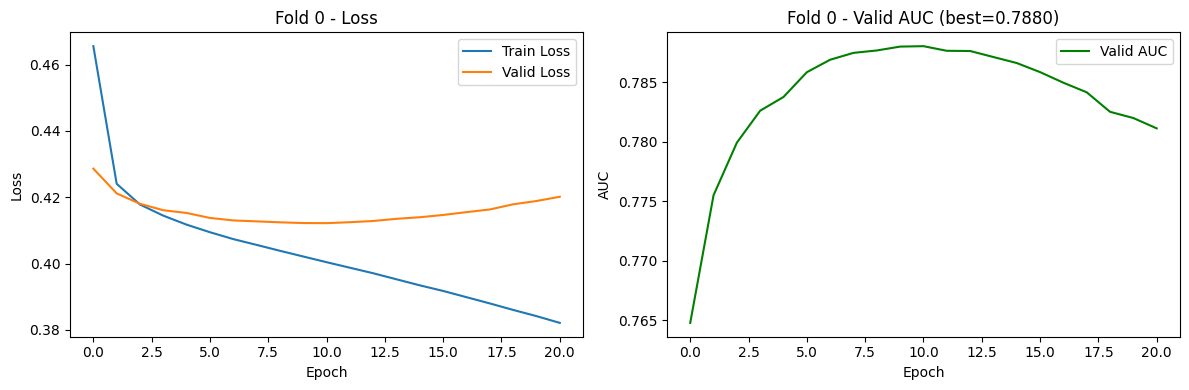

Fold 0 xong. Best valid AUC = 0.7880

FOLD 1


Epoch 1: train_loss=0.4660, val_loss=0.4269, val_auc=0.7648, val_acc=0.8145


Epoch 2: train_loss=0.4247, val_loss=0.4192, val_auc=0.7762, val_acc=0.8177


Epoch 3: train_loss=0.4183, val_loss=0.4159, val_auc=0.7809, val_acc=0.8192


Epoch 4: train_loss=0.4148, val_loss=0.4140, val_auc=0.7831, val_acc=0.8198


...

Epoch 16: train_loss=0.3921, val_loss=0.4126, val_auc=0.7861, val_acc=0.8204


Epoch 17: train_loss=0.3903, val_loss=0.4135, val_auc=0.7850, val_acc=0.8200


Epoch 18: train_loss=0.3883, val_loss=0.4145, val_auc=0.7842, val_acc=0.8197


Epoch 19: train_loss=0.3864, val_loss=0.4153, val_auc=0.7831, val_acc=0.8193


Epoch 20: train_loss=0.3845, val_loss=0.4163, val_auc=0.7824, val_acc=0.8193
Early stopping tại epoch 20


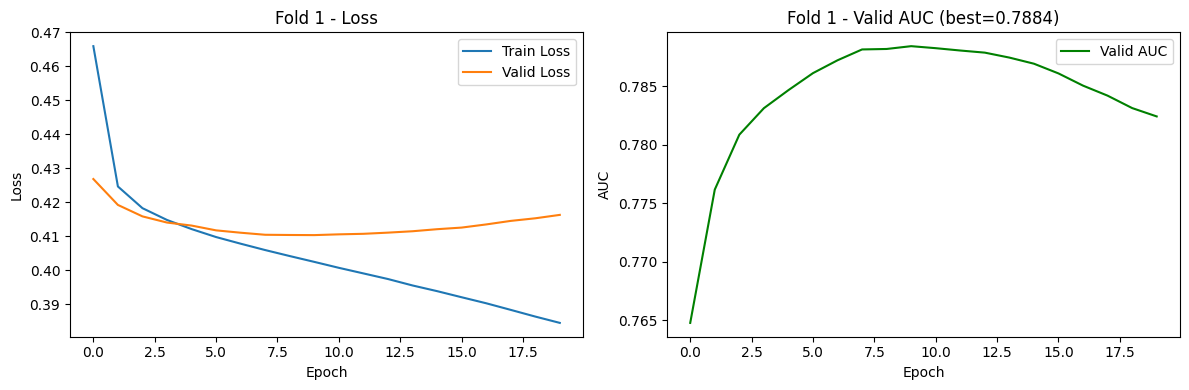

Fold 1 xong. Best valid AUC = 0.7884

FOLD 2


Epoch 1: train_loss=0.4659, val_loss=0.4297, val_auc=0.7698, val_acc=0.8111


Epoch 2: train_loss=0.4241, val_loss=0.4210, val_auc=0.7811, val_acc=0.8151


Epoch 3: train_loss=0.4179, val_loss=0.4180, val_auc=0.7851, val_acc=0.8165


Epoch 4: train_loss=0.4143, val_loss=0.4158, val_auc=0.7879, val_acc=0.8174


...

Epoch 16: train_loss=0.3918, val_loss=0.4143, val_auc=0.7906, val_acc=0.8182


Epoch 17: train_loss=0.3900, val_loss=0.4153, val_auc=0.7895, val_acc=0.8177


Epoch 18: train_loss=0.3883, val_loss=0.4157, val_auc=0.7893, val_acc=0.8175


Epoch 19: train_loss=0.3862, val_loss=0.4168, val_auc=0.7882, val_acc=0.8172


Epoch 20: train_loss=0.3843, val_loss=0.4185, val_auc=0.7871, val_acc=0.8170
Early stopping tại epoch 20


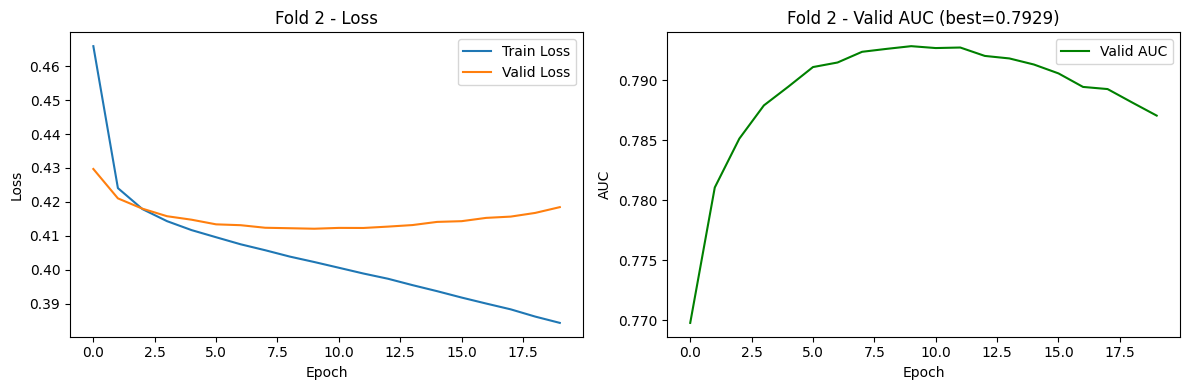

Fold 2 xong. Best valid AUC = 0.7929

FOLD 3


Epoch 1: train_loss=0.4675, val_loss=0.4271, val_auc=0.7657, val_acc=0.8143


Epoch 2: train_loss=0.4251, val_loss=0.4180, val_auc=0.7772, val_acc=0.8180


Epoch 3: train_loss=0.4188, val_loss=0.4150, val_auc=0.7813, val_acc=0.8191


Epoch 4: train_loss=0.4151, val_loss=0.4130, val_auc=0.7843, val_acc=0.8197


...

Epoch 18: train_loss=0.3892, val_loss=0.4134, val_auc=0.7856, val_acc=0.8199


Epoch 19: train_loss=0.3872, val_loss=0.4144, val_auc=0.7848, val_acc=0.8192


Epoch 20: train_loss=0.3853, val_loss=0.4158, val_auc=0.7835, val_acc=0.8186


Epoch 21: train_loss=0.3834, val_loss=0.4167, val_auc=0.7821, val_acc=0.8182


Epoch 22: train_loss=0.3815, val_loss=0.4182, val_auc=0.7813, val_acc=0.8178
Early stopping tại epoch 22


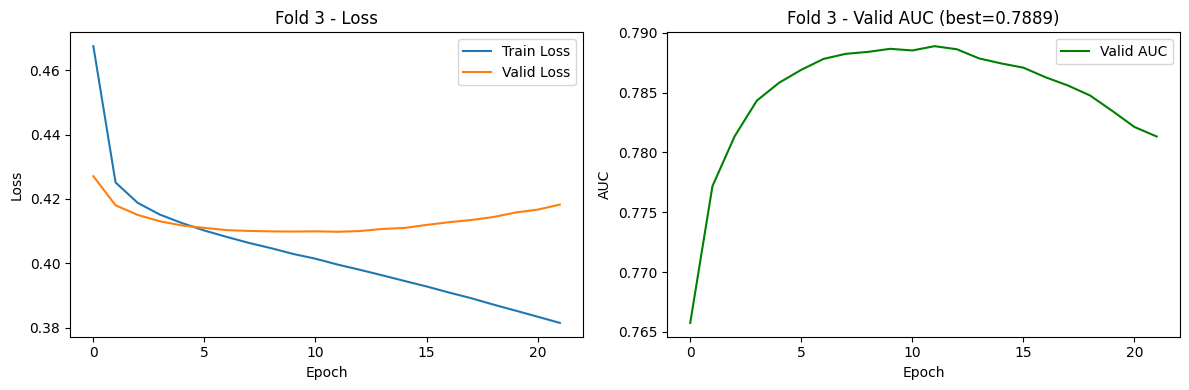

Fold 3 xong. Best valid AUC = 0.7889

FOLD 4


Epoch 1: train_loss=0.4659, val_loss=0.4285, val_auc=0.7663, val_acc=0.8123


Epoch 2: train_loss=0.4241, val_loss=0.4206, val_auc=0.7772, val_acc=0.8159


Epoch 3: train_loss=0.4181, val_loss=0.4175, val_auc=0.7815, val_acc=0.8173


Epoch 4: train_loss=0.4146, val_loss=0.4156, val_auc=0.7843, val_acc=0.8179


...

Epoch 18: train_loss=0.3889, val_loss=0.4155, val_auc=0.7860, val_acc=0.8187


Epoch 19: train_loss=0.3871, val_loss=0.4164, val_auc=0.7853, val_acc=0.8184


Epoch 20: train_loss=0.3851, val_loss=0.4175, val_auc=0.7841, val_acc=0.8175


Epoch 21: train_loss=0.3832, val_loss=0.4187, val_auc=0.7833, val_acc=0.8170


Epoch 22: train_loss=0.3813, val_loss=0.4199, val_auc=0.7818, val_acc=0.8166
Early stopping tại epoch 22


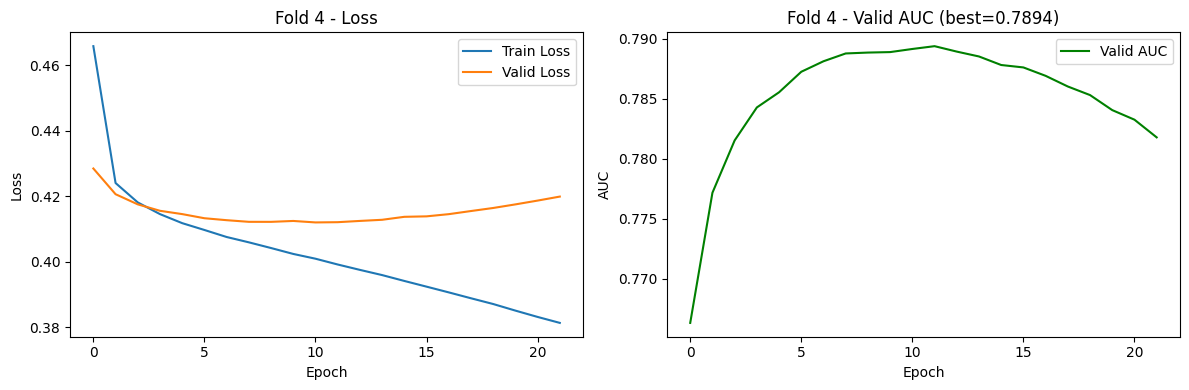

Fold 4 xong. Best valid AUC = 0.7894


In [12]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []
all_histories = []
test_results = []

test_dataset = DKTDataset(df_test, fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

for i in range(5):
    set_seed(config["seed"])
    run_id = make_run_id(config["model"], config["variant"], i, config["seed"])
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    train_dataset = DKTDataset(df_train_valid, fold=i, is_train=True)
    valid_dataset = DKTDataset(df_train_valid, fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model = DKTML(
        num_concepts=config.get('num_concepts', 100),
        embed_dim=config.get('embed_dim', 100),
        hidden_dim=config.get('hidden_dim', 200),
        dropout=config.get('dropout', 0.2)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))

    torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    model, history = dkt_train_epoch(
        model, train_loader, valid_loader, optimizer, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )
    if i == 0:
        leak_check(model, df_train_valid, False, device)
    train_time = time.perf_counter() - t0

    n_ep = len(history["train_loss"])

    extra = {
        "n_epochs": n_ep,
        "train_time_s": train_time,
        "sec_per_epoch": train_time / n_ep,
        "peak_mem_gb": torch.cuda.max_memory_allocated() / 2**30,
        "n_params": sum(p.numel() for p in model.parameters() if p.requires_grad)
    }

    hist = {k: history[k] for k in ("train_loss", "valid_loss", "valid_auc")}

    metrics, q_preds_raw, q_preds_grouped = dkt_evaluate(model, test_loader, device, True, question_level=True)
    metrics["fold"] = i
    save_run(run_id=run_id, config={**config, "fold": i}, metrics=metrics, history=hist, q_preds=q_preds_grouped, extra=extra, model=model, q_preds_raw=q_preds_raw)

    trained_models.append(model)
    all_histories.append(history)
    test_results.append(metrics)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")


TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.7884 ± 0.0002
ACC       : 0.8188 ± 0.0003
RMSE      : 0.3614 ± 0.0001
BRIER     : 0.1306 ± 0.0001
ECE       : 0.0052 ± 0.0012
AUPRC_WRONG: 0.5179 ± 0.0004
F1_WRONG  : 0.3832 ± 0.0068


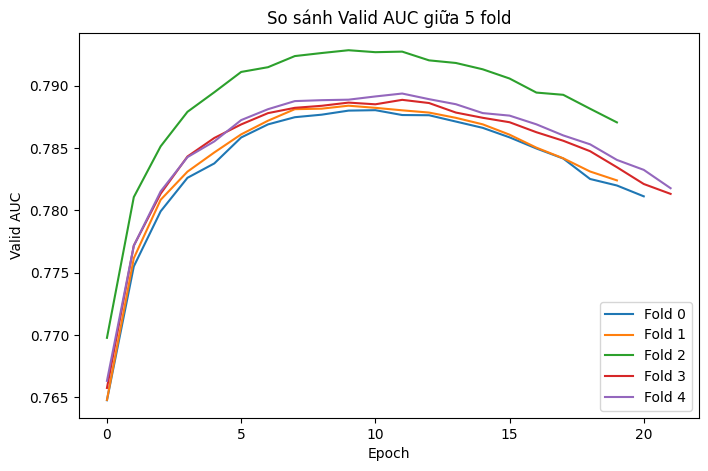

In [13]:
metric_names = ["auc", "acc", "rmse", "brier", "ece", "auprc_wrong", "f1_wrong"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")

plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()